# Separating recorded shot context from conversion

Joseph Smarrelli · September 2026

This notebook recalculates selected findings from the included derived tables. It does not refit the underlying models. See the repository README for the complete source-data build and the accompanying article for interpretation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import json
from IPython.display import display, Image
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
p = root / 'projects' / '05_shot_quality'

## Recalculate the result
The assertions check that the article’s reported quantities agree with the delivered tables.

In [2]:
from sklearn.metrics import log_loss, roc_auc_score, brier_score_loss
d = pd.read_csv(p / 'evaluation_rows.csv.gz')
s = pd.read_csv(p / 'summary.csv').iloc[0]
assert not d.duplicated(['game_id', 'game_event_id']).any()
model_loss = log_loss(d.shot_made_flag, d.p_make)
baseline_loss = log_loss(d.shot_made_flag, d.baseline)
assert np.isclose(model_loss, s.log_loss)
assert np.isclose(baseline_loss, s.baseline_log_loss)
display(pd.DataFrame({'model': [model_loss, roc_auc_score(d.shot_made_flag, d.p_make), brier_score_loss(d.shot_made_flag, d.p_make)], 'zone_baseline': [baseline_loss, roc_auc_score(d.shot_made_flag, d.baseline), brier_score_loss(d.shot_made_flag, d.baseline)]}, index=['log_loss', 'AUC', 'Brier']))

,model,zone_baseline
log_loss,0.636605,0.657231
AUC,0.663176,0.636684
Brier,0.223865,0.232273


## Inspect the estimates

In [3]:
display(pd.read_csv(p / 'team_shot_quality.csv'))

,team_id,attempts,expected_points,actual_points,expected_pps,actual_pps,making_per_100,tricode
0,1610612743,7196,7716.403209,8301,1.072318,1.153558,8.123913,DEN
1,1610612747,6863,7381.249541,7866,1.075514,1.146146,7.063244,LAL
2,1610612738,7398,7718.232837,8180,1.043286,1.105704,6.241784,BOS
3,1610612746,6857,7325.918200,7663,1.068385,1.117544,4.915879,LAC
4,1610612749,7012,7671.453929,7930,1.094046,1.130918,3.687194,MIL
5,1610612760,7307,7994.051148,8203,1.094026,1.122622,2.859571,OKC
6,1610612758,7299,7473.965841,7659,1.023971,1.049322,2.535062,SAC
7,1610612744,7280,7853.210994,8000,1.078738,1.098901,2.016333,GSW
8,1610612766,7292,7924.274767,8057,1.086708,1.104909,1.820149,CHA
9,1610612745,7362,7864.082927,7986,1.068199,1.084760,1.656032,HOU


## Figures

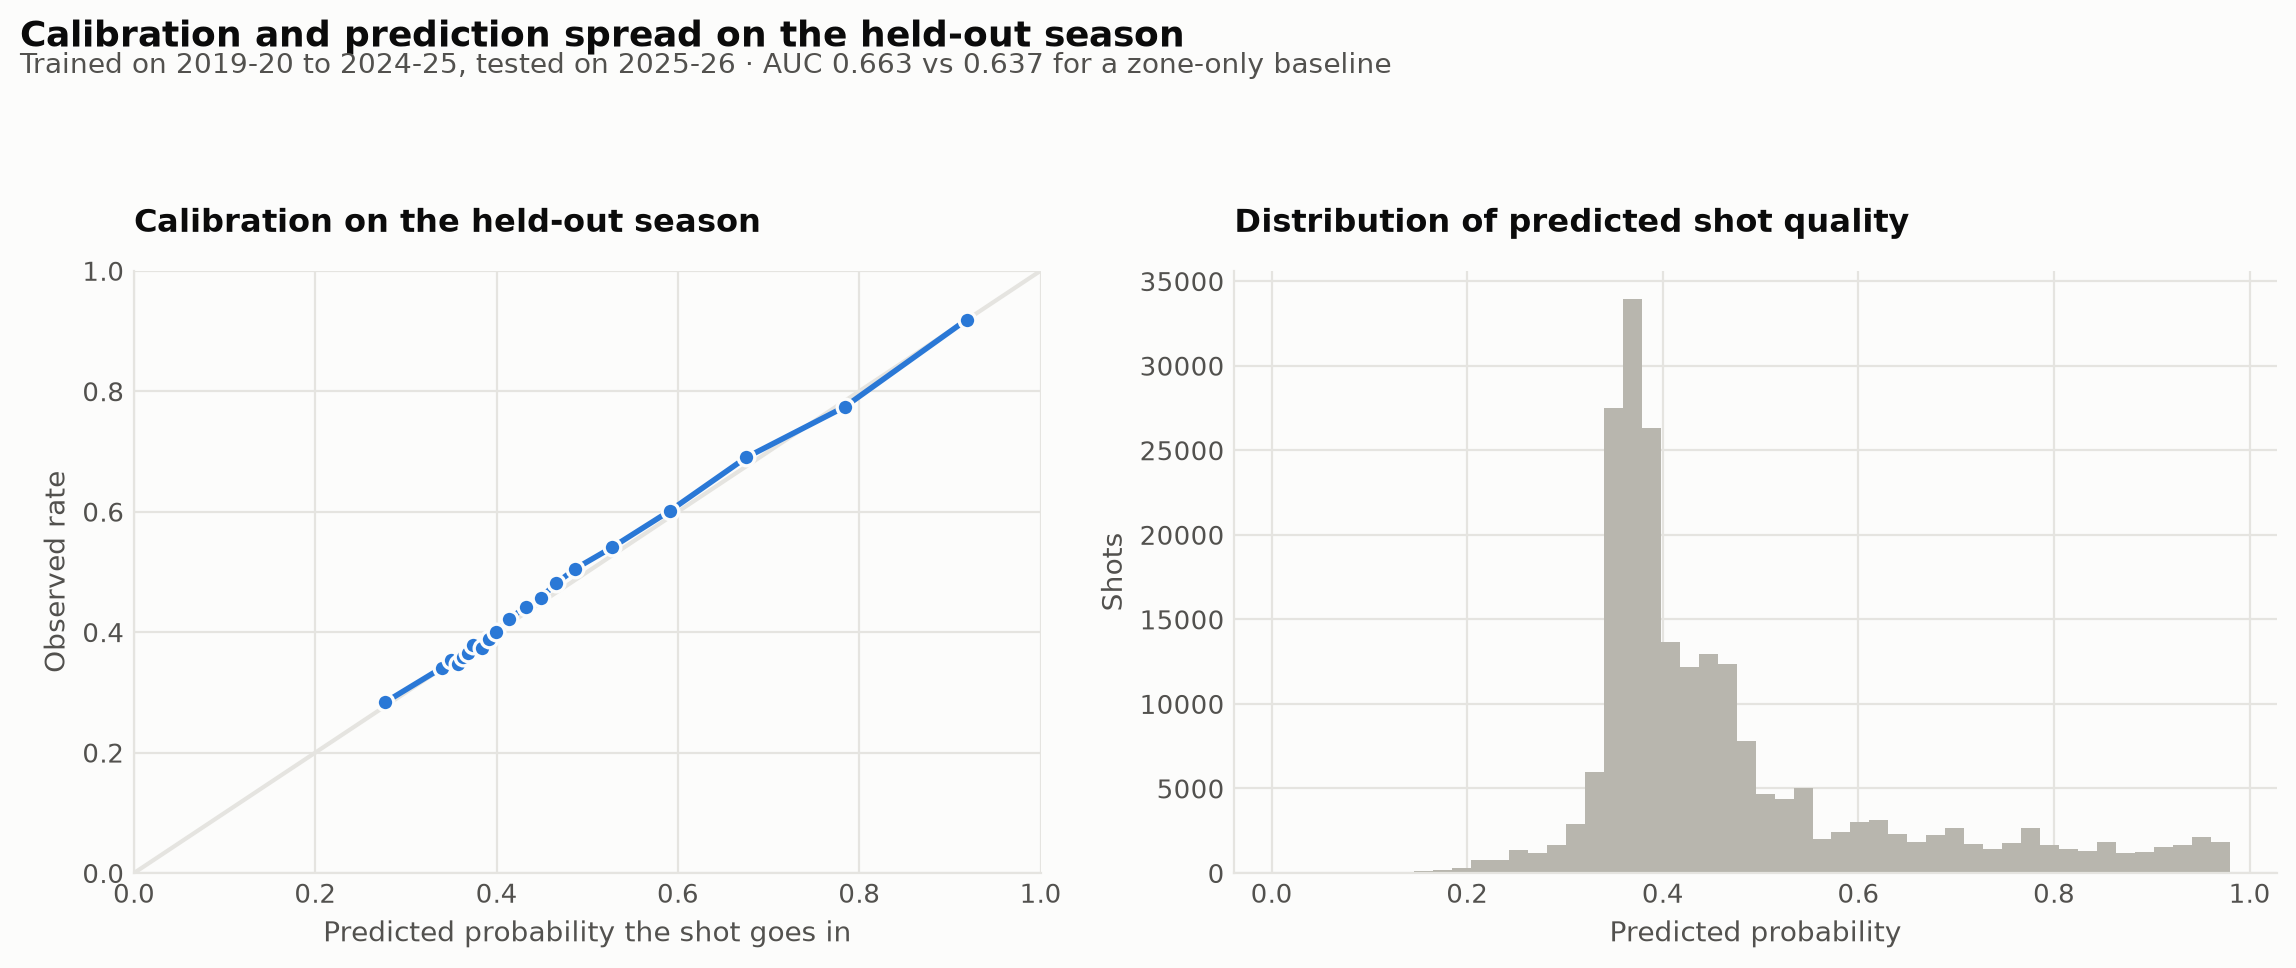

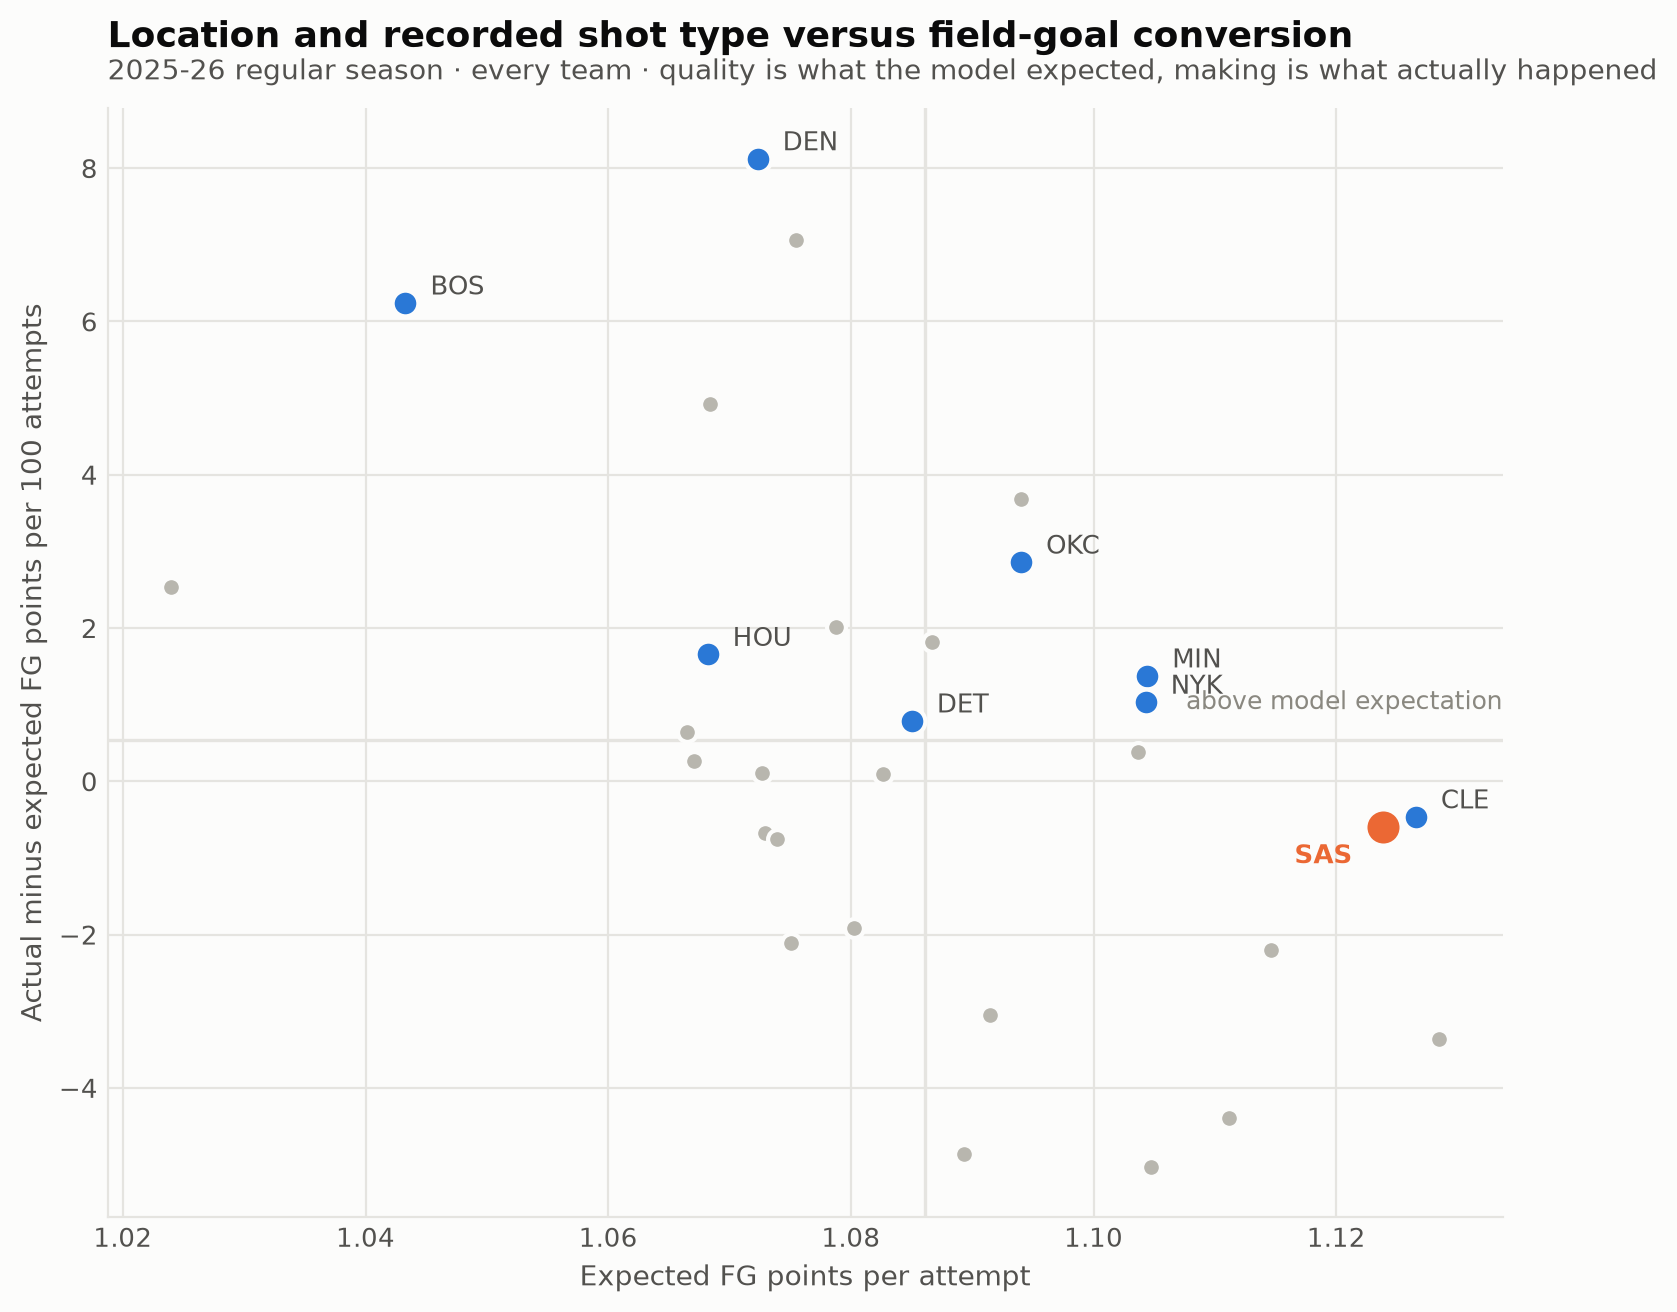

In [4]:
display(Image(filename=str(root / 'projects/05_shot_quality/figures/calibration.png')))
display(Image(filename=str(root / 'projects/05_shot_quality/figures/quality_vs_making.png')))

## Interpretation limits
The model conditions on recorded attempts and action labels. It includes heaves and does not observe shot contests, tracking, shooter ability or shots a player declined to take.